In [2]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

train_data = datasets.MNIST(root="/content/mnist", train=True,
                            download=True, transform=transforms.ToTensor())
test_data = datasets.MNIST(root="/content/mnist", train=False,
                           download=True, transform=transforms.ToTensor())

print(len(train_data), len(test_data))

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 646kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.70MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 16.1MB/s]

60000 10000


torch.Size([1, 28, 28]) torch.float32
0.0 1.0
5


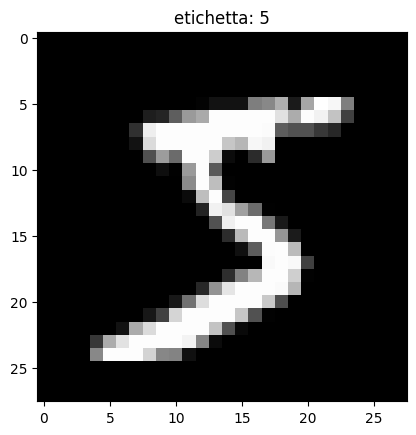

In [ ]:
img, label = train_data[0]
print(img.shape, img.dtype)
print(img.min().item(), img.max().item())
print(label)

plt.imshow(img.squeeze(), cmap="gray")
plt.title(f"etichetta: {label}")
plt.show()

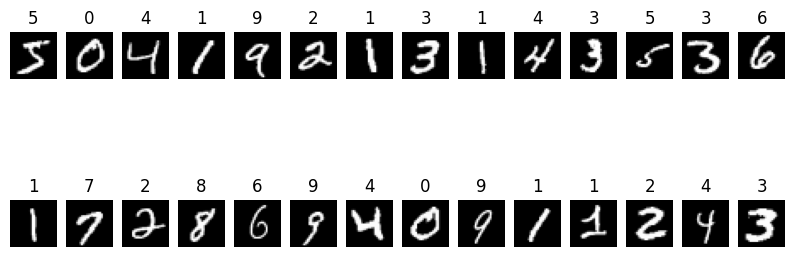

In [ ]:
fig, axes = plt.subplots(2, 14, figsize=(10, 4))
for i, ax in enumerate(axes.flatten()):
    img, label = train_data[i]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(label)
    ax.axis("off")
plt.show()

In [ ]:
print(train_data.targets.bincount())

tensor([5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949])


In [3]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

xb, yb = next(iter(train_loader))
print(xb.shape, yb.shape)

torch.Size([64, 1, 28, 28]) torch.Size([64])


In [ ]:
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 10),
)
print(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=10, bias=True)
)


In [ ]:
out = model(xb)
print(out.shape)
print(out[0])

torch.Size([64, 10])
tensor([ 0.0995, -0.0358, -0.1474, -0.2206, -0.1371,  0.0708,  0.1434,  0.1215,
         0.0525, -0.0123], grad_fn=<SelectBackward0>)


In [ ]:
pred = out.argmax(dim=1)
print(pred[:10])
print(yb[:10])
print((pred == yb).float().mean().item())

tensor([6, 5, 5, 9, 3, 5, 6, 0, 1, 4])
tensor([4, 5, 4, 2, 3, 8, 4, 9, 9, 3])
0.109375


ORA TUTTO IL CICLO COMPLETO ADDESTRAMENTO

In [9]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [11]:
model = nn.Sequential(nn.Flatten(), nn.Linear(784, 10)).to(device)

loss_fn = nn.CrossEntropyLoss() # più il modello è sicuro della cifra sbagliata, più la loss è alta
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

In [12]:
xb, yb = next(iter(train_loader))
xb, yb = xb.to(device), yb.to(device)
print(loss_fn(model(xb), yb).item())

2.3056092262268066


In [13]:
for epoch in range(3):
    total = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(xb)
        loss = loss_fn(out, yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(xb)

    print(epoch, round(total / len(train_data), 4))

0 0.4771
1 0.3368
2 0.3142


In [ ]:
print(next(model.parameters()).device)

cuda:0


In [14]:
def accuracy(model, loader):
    correct = 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            correct += (model(xb).argmax(dim=1) == yb).sum().item()
    return correct / len(loader.dataset)

print("train:", accuracy(model, train_loader))
print("test: ", accuracy(model, test_loader))

train: 0.9155666666666666
test:  0.9175


In [15]:
from torch.utils.data import Subset

small_data = Subset(train_data, range(500))
small_loader = DataLoader(small_data, batch_size=50, shuffle=True)

model_s = nn.Sequential(nn.Flatten(), nn.Linear(784, 10)).to(device)
optimizer_s = torch.optim.SGD(model_s.parameters(), lr=0.1)

for epoch in range(200):
    for xb, yb in small_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer_s.zero_grad()
        loss = loss_fn(model_s(xb), yb)
        loss.backward()
        optimizer_s.step()

    if epoch % 20 == 0 or epoch == 199:
        print(epoch,
              round(accuracy(model_s, small_loader), 3),
              round(accuracy(model_s, test_loader), 3))

0 0.772 0.659
20 0.944 0.819
40 0.984 0.83
60 0.994 0.832
80 1.0 0.832
100 1.0 0.833
120 1.0 0.833
140 1.0 0.833
160 1.0 0.834
180 1.0 0.834
199 1.0 0.834


AGGIUNTO IL VALIDATION

In [16]:
train_s = Subset(train_data, range(0, 500))
val_s = Subset(train_data, range(500, 1500))

train_s_loader = DataLoader(train_s, batch_size=50, shuffle=True)
val_s_loader = DataLoader(val_s, batch_size=100, shuffle=False)

model_v = nn.Sequential(nn.Flatten(), nn.Linear(784, 10)).to(device)
optimizer_v = torch.optim.SGD(model_v.parameters(), lr=0.1)

val_accs = []
for epoch in range(200):
    for xb, yb in train_s_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer_v.zero_grad()
        loss = loss_fn(model_v(xb), yb)
        loss.backward()
        optimizer_v.step()
    val_accs.append(accuracy(model_v, val_s_loader))

best = max(val_accs)
best_epoch = val_accs.index(best)
print("migliore:", round(best, 3), "all'epoca", best_epoch)
print("alla fine:", round(val_accs[-1], 3))

migliore: 0.804 all'epoca 48
alla fine: 0.794


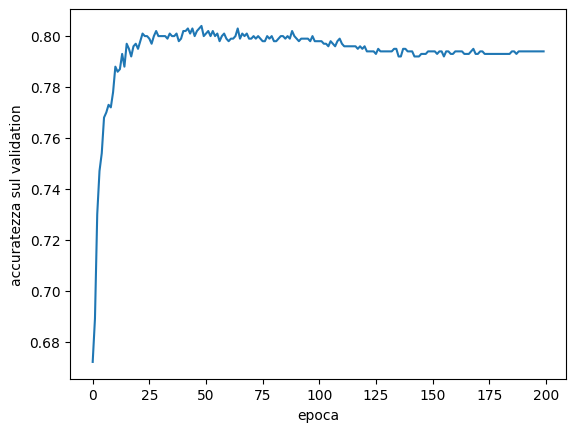

In [17]:
plt.plot(val_accs)
plt.xlabel("epoca")
plt.ylabel("accuratezza sul validation")
plt.show()

In [18]:
import copy

model_e = nn.Sequential(nn.Flatten(), nn.Linear(784, 10)).to(device)
optimizer_e = torch.optim.SGD(model_e.parameters(), lr=0.1)

best_val = 0.0
best_state = None
patience = 20
wait = 0

for epoch in range(200):
    for xb, yb in train_s_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer_e.zero_grad()
        loss = loss_fn(model_e(xb), yb)
        loss.backward()
        optimizer_e.step()

    val = accuracy(model_e, val_s_loader)

    if val > best_val:
        best_val = val
        best_state = copy.deepcopy(model_e.state_dict())
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            print("mi fermo all'epoca", epoch)
            break

model_e.load_state_dict(best_state)
print("val migliore:", round(best_val, 3))
print("test:", round(accuracy(model_e, test_loader), 3))

mi fermo all'epoca 51
val migliore: 0.806
test: 0.826
